# Support Ticket Analysis

## 1. Objective

The objective of this analysis is to examine customer support tickets to understand support demand, ticket resolution times, ticket priorities, and customer satisfaction. The analysis aims to identify patterns that could help improve support operations and customer experience.

## 2. Business Questions

1. How are support tickets distributed across ticket categories?
2. How many tickets fall into each priority level?
3. How long does it take to resolve support tickets?
4. Which ticket categories take the longest to resolve?
5. How does customer satisfaction vary across ticket categories and priorities?
6. Is resolution time associated with customer satisfaction?


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

tickets=pd.read_csv(r"../data/raw/ravenstack_support_tickets.csv")

print("Dataset Shape:",tickets.shape)

print("Datasets Columns: ",tickets.columns.to_list())

print("Dataset's Data Types")

display(tickets.dtypes)

display(tickets.head())

Dataset Shape: (2000, 9)
Datasets Columns:  ['ticket_id', 'account_id', 'submitted_at', 'closed_at', 'resolution_time_hours', 'priority', 'first_response_time_minutes', 'satisfaction_score', 'escalation_flag']
Dataset's Data Types


ticket_id                          str
account_id                         str
submitted_at                       str
closed_at                          str
resolution_time_hours          float64
priority                           str
first_response_time_minutes      int64
satisfaction_score             float64
escalation_flag                   bool
dtype: object

,ticket_id,account_id,submitted_at,closed_at,resolution_time_hours,priority,first_response_time_minutes,satisfaction_score,escalation_flag
0,T-0024de,A-712f1c,2023-07-27,2023-07-28 03:00:00,27.0,high,74,NaN,False
1,T-4d04b9,A-e43bf7,2024-07-08,2024-07-09 03:00:00,27.0,urgent,144,NaN,False
2,T-d5e12f,A-0f3e88,2024-10-17,2024-10-17 19:00:00,19.0,urgent,93,4.0,False
3,T-dfce9a,A-4c56c9,2024-09-08,2024-09-09 23:00:00,47.0,medium,126,5.0,False
4,T-c59f77,A-6f8ad2,2024-11-30,2024-12-01 02:00:00,26.0,medium,8,NaN,False


How many support tickets fall into each priority level?

In [6]:
priority_count=tickets['priority'].value_counts()

priority_analysis=priority_count.reset_index()

priority_analysis.columns=["priority","ticket_count"]

priority_analysis['ticket_share_pct']=(
    priority_analysis['ticket_count']/len(tickets)*100
)

display(priority_analysis.round(2))


,priority,ticket_count,ticket_share_pct
0,urgent,514,25.70
1,high,510,25.50
2,medium,491,24.55
3,low,485,24.25


How long does it take to resolve support tickets?

- This analysis examines the time required to resolve support tickets. It calculates the average, median, minimum, and maximum resolution times to understand overall support performance and identify potential differences between typical and unusually long-running tickets.

In [9]:
resolution_summary=tickets['resolution_time_hours'].describe()

display(resolution_summary.round(2))

count    2000.00
mean       35.86
std        21.14
min         1.00
25%        17.00
50%        35.00
75%        54.00
max        72.00
Name: resolution_time_hours, dtype: float64

Which ticket categories take the longest to resolve?

In [11]:
priority_resolution = (
    tickets.groupby("priority")["resolution_time_hours"]
    .agg(
        ticket_count="count",
        average_resolution_hours="mean",
        median_resolution_hours="median",
        min_resolution_hours="min",
        max_resolution_hours="max"
    )
    .reset_index()
)

display(priority_resolution.round(2))

,priority,ticket_count,average_resolution_hours,median_resolution_hours,min_resolution_hours,max_resolution_hours
0,high,510,36.96,38.0,1.0,72.0
1,low,485,36.35,36.0,1.0,72.0
2,medium,491,35.59,34.0,1.0,72.0
3,urgent,514,34.57,33.0,1.0,72.0


How does customer satisfaction vary across ticket categories and priorities?

In [13]:
satisfaction_by_priority = (
    tickets.groupby("priority")["satisfaction_score"]
    .agg(
        responses="count",
        average_satisfaction="mean",
        median_satisfaction="median"
    )
    .reset_index()
)


display(satisfaction_by_priority.round(2))

,priority,responses,average_satisfaction,median_satisfaction
0,high,295,4.00,4.0
1,low,287,4.02,4.0
2,medium,292,3.93,4.0
3,urgent,301,3.97,4.0


Is resolution time associated with customer satisfaction?

In [17]:
satisfaction_tickets=tickets.dropna(
    subset=["resolution_time_hours", "satisfaction_score"]
)

correlation=satisfaction_tickets[
    ["resolution_time_hours", "satisfaction_score"]
].corr().iloc[0,1]

print(f"Number of tickets analysed: {len(satisfaction_tickets)}")
print(f"Correlation coefficient: {correlation:.3f}")

Number of tickets analysed: 1175
Correlation coefficient: 0.012


This analysis compares escalated and non-escalated support tickets to examine differences in ticket volume and resolution time. The findings may help identify whether escalated tickets require more time to resolve.

In [18]:
escalation_analysis = tickets.groupby("escalation_flag")[
    "resolution_time_hours"
].agg(
    ticket_count="count",
    average_resolution_hours="mean",
    median_resolution_hours="median"
).reset_index()

display(escalation_analysis.round(2))

,escalation_flag,ticket_count,average_resolution_hours,median_resolution_hours
0,False,1905,35.79,35.0
1,True,95,37.20,39.0


Visualize resolution time by priority

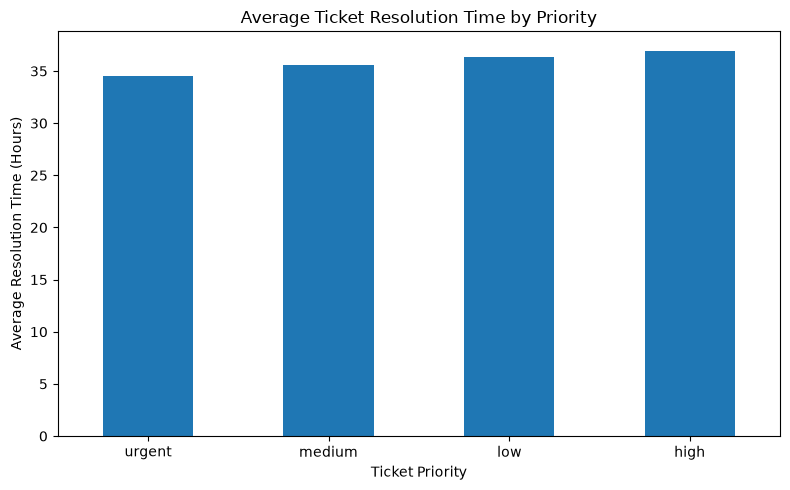

In [19]:
priority_resolution = (
    tickets.groupby("priority")["resolution_time_hours"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(8, 5))
priority_resolution.plot(kind="bar")

plt.title("Average Ticket Resolution Time by Priority")
plt.xlabel("Ticket Priority")
plt.ylabel("Average Resolution Time (Hours)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Support Ticket Analysis Conclusion

The support ticket analysis examined 2,000 tickets to understand ticket priorities, resolution times, customer satisfaction, and escalation patterns.

The average ticket resolution time was 35.86 hours, with a median of 35 hours. Urgent tickets had the lowest average resolution time, while high-priority tickets had the highest. Customer satisfaction scores were relatively similar across priority levels, and the correlation between resolution time and satisfaction was approximately 0.012, indicating almost no linear relationship. Escalated tickets had a slightly higher average resolution time than non-escalated tickets.

These findings provide an overview of support operations and highlight areas for further investigation. However, the observed relationships do not establish causation, and missing satisfaction scores limit the customer satisfaction analysis.

See `docs/support_ticket_analysis_report.md` for the detailed findings and business recommendations.